# Final project

**Course title:** Computer Simulation Methods in Physics (Phys 4071/5071; Fall 2025)  
**This project is due on Friday, December 12, 2025, at 11:59 pm Eastern Time.** 
(Submission via the shared `GitHub` repository.)

## Rules:

* You can use all resources discussed in the lecture except other human and AI resources, including `ChatGPT`. **Collaborations with other students are not allowed.**
* Please answer the questions in this `Jupyter` notebook and use `Python3` for your computations. Solutions in other programming languages will not be accepted.
* Feel free to ask the [lead instructor](https://github.com/ohiou-inpp-ntg/2025-phys-4071-5071#general-information) questions to help you understand the exercises.
* **Document your programs** adequately so we know that you understand your code. Your functions should have at least a one-line [docstring](https://peps.python.org/pep-0257/) that explains their purpose.
* Points will be deducted for programs returning warnings and/or not running from the top to the bottom of the Jupyter Notebook. Before you submit your solution, we recommend **restarting the kernel and running all cells from the top to the bottom**, e.g., using `Kernel > Restart & Run All`.
* Label your plots adequately, e.g., so we know what is plotted, in what **units**, and what the axes mean. Show legends with meaningful labels if more than one dataset is plotted.
* Explain your solutions and analytic calculations clearly through coherent text and, if necessary, $\LaTeX$ expressions in `markdown` cells.
* Submit your project like any previous homework (i.e., via the shared GitHub repository) _before_ the deadline (see above). **Submission must be done before the deadline to be accepted.** 
* If you encounter technical issues during the submission process, try to upload your project manually as described [here](https://docs.github.com/en/repositories/working-with-files/managing-files/adding-a-file-to-a-repository). If that does not work, email your solutions to the [lead instructor](https://github.com/ohiou-inpp-ntg/2025-phys-4071-5071#general-information) _before_ the deadline and explain the technical issue.

**Good luck!**

------

## Solar Cycle (5 points)

The attached file [`sunspots.txt`](./sunspots.txt) contains the observed number of sunspots of the Sun for each month since January 1749. The file contains two columns of numbers: the first column represents the month (relative to the first record), and the second column represents the sunspot number, which is a derived quantity, not just a raw count. 

Complete the following exercises to analyze the data:

1. Write a program that reads the data in the file and makes a graph of sunspots a function of time. Make the $x$-axis in units of years. 
2. You should see that the number of sunspots has fluctuated on a regular cycle for as long as observations have been recorded. Estimate (roughly) the length of the cycle in years.
3. Compute the Fourier transform of the sunspot data and make a graph of the magnitude squared $|c_k|^2$ of the Fourier coefficients as a function of the frequency. You may use library implementations of the Fourier transform. What is the unit of the frequency? This graph is also called the power spectrum of the sunspot signal.
4. You should see that there is a noticeable peak in the power spectrum at a nonzero frequency. What does this peak tell us?
5. Find the approximate frequency to which the peak corresponds. Print it out to six decimal places using formated strings. Does your result match your rough estimate in Exercise 2?
6. Smooth the sunspot data by removing all variability with periods of 6 years or shorter in the data. Plot the resulting smoothed signal.

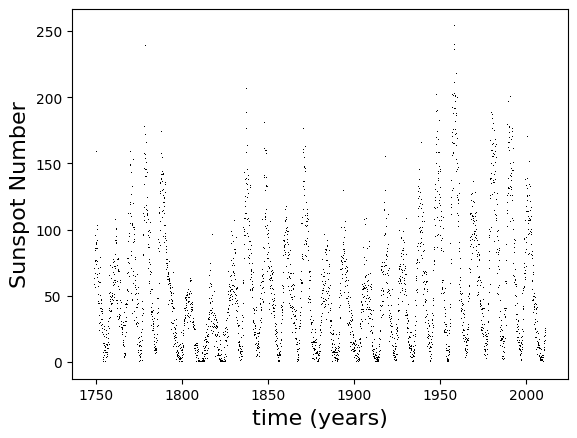

In [1]:
#Solar Cycle, 1.) 
import numpy as np
import matplotlib.pyplot as plt

# Sunspot Data; load data 
data = np.loadtxt("sunspots.txt")

#x and y-axis data extracted from columns 
months = data[:, 0]
sunspots = data[:, 1]

#months to years conversion starting 1749
years = 1749.0 + months/12.0

#plotting data from extracted text
plt.plot(years, sunspots,  linestyle='', marker=',', color='black')
plt.xlabel("time (years)", fontsize=16)
plt.ylabel("Sunspot Number", fontsize=16)
plt.show()

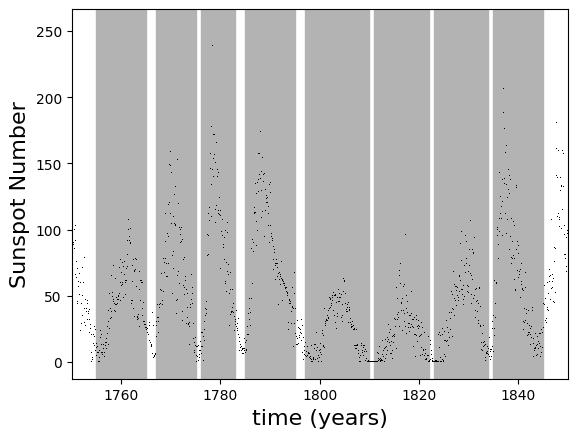

C_l (1,2) C_2 (3,4) C_3 (5,6) C_4 (7,8)
    11.00     10.50     13.00     11.50

 (average length of cycle) T (Period) =  11.500000 years

 (frequency of oscillation) f =  0.086957 1/yrs


In [2]:
#Solar Cycle, 2.) 
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 


# Sunspot Data; load data 
data = np.loadtxt("sunspots.txt")

#x and y-axis data extracted from columns 
months = data[:, 0] #unit: recorded data in months
sunspots = data[:, 1] #unit: counts of sunspots

#months to years conversion starting 1749
years = 1749.0 + months/12.0

#plotting data from extracted text; use limited x-range 1750-1850
plt.plot(years, sunspots,  linestyle='', marker=',', color='black')
#within plot grayscale will be used to capture the peaks, which gives a visual inspection estimate to find peak centers 
#(ignore cutoff peaks essentally 1st peak and last peak in spectra)
plt.axvspan(1755.0, 1765.0, color="0.7", zorder=0)
plt.axvspan(1767.0, 1775.0, color="0.7", zorder=0)
plt.axvspan(1776.0, 1783.0, color="0.7", zorder=0)
plt.axvspan(1785.0, 1795.0, color="0.7", zorder=0)
plt.axvspan(1797.0, 1810.0, color="0.7", zorder=0)
plt.axvspan(1811.0, 1822.0, color="0.7", zorder=0)
plt.axvspan(1823.0, 1834.0, color="0.7", zorder=0)
plt.axvspan(1835.0, 1845.0, color="0.7", zorder=0)
plt.xlabel("time (years)", fontsize=16)
plt.ylabel("Sunspot Number", fontsize=16)
plt.xlim(1750,1850)
plt.show()

#8 peaks overall; now peak centers = (RangeL + RangeR)/2.0 for each peak 
PC_1 = (1755.0 + 1765.0)/2.0 
PC_2 = (1767.0 + 1775.0)/2.0 
PC_3 = (1776.0 + 1783.0)/2.0 
PC_4 = (1785.0 + 1795.0)/2.0 
PC_5 = (1797.0 + 1810.0)/2.0 
PC_6 = (1811.0 + 1822.0)/2.0 
PC_7 = (1823.0 + 1834.0)/2.0 
PC_8 = (1835.0 + 1845.0)/2.0 


#Now with peak centers calculated and stored, every eight peaks will be assigned in pairs (1,2), (3,4), (5,6), (7,8), and essentially 
#these pairs' peak centers will be subtracted from each other to give a rough estimate on the cycle (ex., cycle (from(1,2)) = PC1 - PC2) 
#Roughly, each process step of measuring the cycle for each pair should be about the same (displayed as Panda Frame) 

Table = [] 
Table.append({
    "C_l (1,2)": f"{abs(PC_1 - PC_2):.2f}", 
    "C_2 (3,4)": f"{abs(PC_3 - PC_4):.2f}", 
    "C_3 (5,6)": f"{abs(PC_5 - PC_6):.2f}", 
    "C_4 (7,8)": f"{abs(PC_7 - PC_8):.2f}", 
})

y = pd.DataFrame(Table).to_string(index=False)
print(y)  


#Rough estimate measurement of the cycle will be based on taking the mean of each cycle's measurements, C_mean = (C1 + C2 + C3 + C4)/4
C_mean = (abs(PC_1 - PC_2) + abs(PC_3 - PC_4) + abs(PC_5 - PC_6) + abs(PC_7 - PC_8))/4.0 #unit: years
print(f"\n (average length of cycle) T (Period) = {C_mean: .6f} years")
print(f"\n (frequency of oscillation) f = {1.0/C_mean: .6f} 1/yrs")




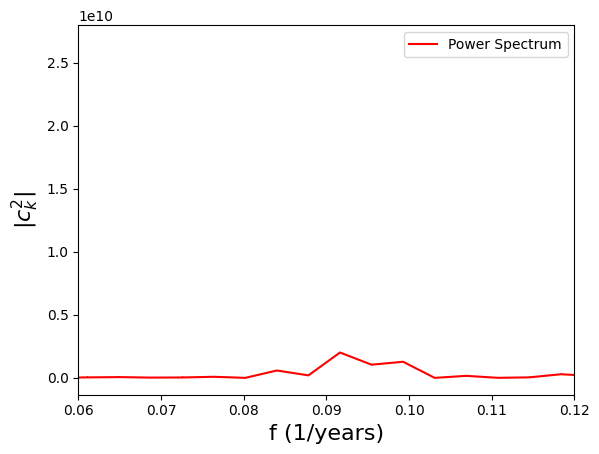

The unit of frequency is based on cycles/yrs or in terms yrs^-1


In [3]:
#Solar Cycle, 3.) 
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
from numpy.fft import rfft, irfft, rfftfreq

# Sunspot Data; load data 
data = np.loadtxt("sunspots.txt")

#x and y-axis data extracted from columns 
months = data[:, 0]
sunspots = data[:, 1]

#FFT and squaring coefficients
c = rfft(sunspots)
c_square = pow(abs(c), 2) 

#months to years conversion 
y = months/12.0 

#sampling (essentially defining frequency here)
dt = 1.0/12.0 #sampling intervals in yrs unit
N = len(sunspots) #total number of data points
freq = rfftfreq(N, d=dt) #frequency unit: yrs^(-1) 

#Final plotting; plot for |c_k|^2 vs frequency 
plt.plot(freq, c_square, linestyle='-', marker=',', color='red', label="Power Spectrum")
plt.xlabel("f (1/years)", fontsize=16)
plt.ylabel("|$c_k^{2}$|", fontsize=16)
plt.xlim(0.06, 0.12)
plt.legend()
plt.show()

print("The unit of frequency is based on cycles/yrs or in terms yrs^-1") 



**Solar Cycle, 4.)**

The Peak that is visibly shown in the power spectra can be thought of as a
natural resonance of the system, more or less, that resonance correlates to a physical oscillation that defines the sunspot system.


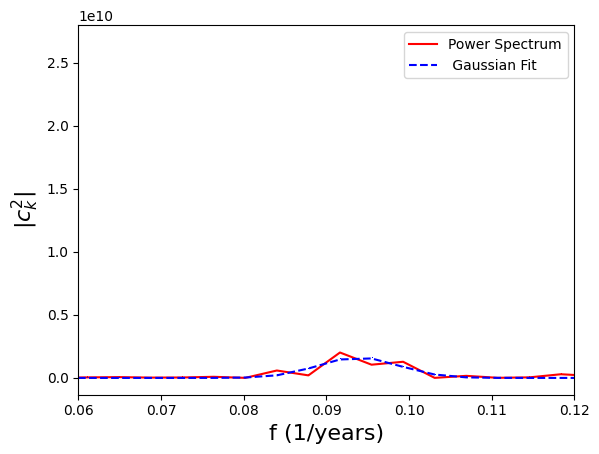

----------Fit Parameters----------

A_f = 1628283025.567310 

mu_f = 0.093875 

sigma_f = 0.004851

(resonant frequency extraction) resonant frequency from fit: f_r = 0.093875; resonant frequency from visual averaging: f_avg = 0.086957; relative error = 0.691876 %

 based on relative error bing .6 % different frequencies from both approaches can be approxiamate enough


In [4]:
#Solar Cycle, 5.) 
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
from scipy.optimize import curve_fit
from numpy.fft import rfft, irfft, rfftfreq

#plan of action: fit aramater mu from the Gaussian fit should give the frequency that corresponds to the resonant center. 

#pre-define arrays 
freq1 = freq[15:30] 
c_square1 = c_square[15:30]

#Gaussian-Like Function 
def Gauss(x, A, mu, sigma):
    """ This function defines the base general form of a Gaussian that will be used to model resonant peak. 

    Parameters:
    ----------
    x, A, mu, sigma: array and float type 
    Essentially, the inputs are the independent variables used to model and fit the parameters A, mu, and sigma. 

    Return: 
    -------
    numpy array 
    Essentially returns an array of Gaussian modeling values, which can be used for fitting purposes. 

    """
    return A * np.exp(-(x - mu)**2 / (2.0 * sigma**2))

#Use curve_fit to get parameters, the Gaussian fit-array has initial guesses 
A0 = np.max(c_square1)
mu0 = 0.085
#spread that can capture the resonant area
sigma0 = (freq1.max() - freq1.min()) / 3
p0 = [A0, mu0, sigma0]
Par, error = curve_fit(Gauss, freq, c_square, p0=p0)
A_f, mu_f, sigma_f = Par 
fit_G = Gauss(freq, A_f, mu_f, sigma_f) 

#displaying plotting of power spectrum and Gaussian fitting
plt.plot(freq, c_square, linestyle='-', marker=',', color='red', label="Power Spectrum")
plt.plot(freq, fit_G, linestyle='--', marker=',', color='blue', label=" Gaussian Fit")
plt.xlabel("f (1/years)", fontsize=16)
plt.ylabel("|$c_k^{2}$|", fontsize=16)
plt.xlim(0.06, 0.12)
plt.legend()
plt.show()

#Fit parameters displayed 
print(f"----------Fit Parameters----------\n")
print(f"A_f = {A_f:.6f} \n")
print(f"mu_f = {mu_f:.6f} \n")
print(f"sigma_f = {sigma_f:.6f}\n")


#Obtaining the resonant frequency and relative error (comparison to ex 2.)
f_r = mu_f 
f_ex_2 = (1.0/C_mean) 
rel_err = abs(f_r - f_ex_2)
print(f"(resonant frequency extraction) resonant frequency from fit: f_r = {f_r:.6f}; resonant frequency from visual averaging: f_avg = {f_ex_2:.6f}; relative error = {rel_err * 100.0:.6f} %")
print("\n based on relative error bing .6 % different frequencies from both approaches can be approxiamate enough")



number of coefficients = 43 (compression rate: 97.3%)


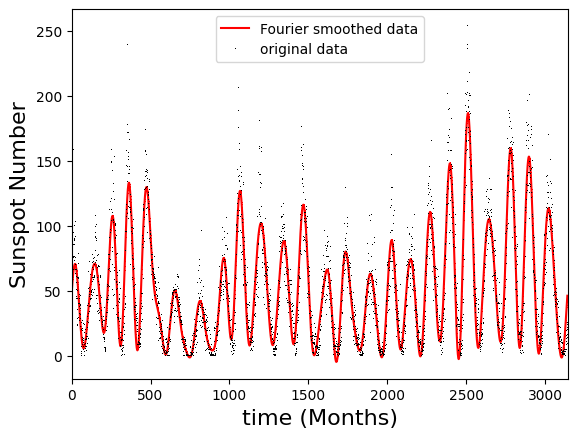

In [5]:
#Solar Cycle, 6.) 
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
from numpy.fft import rfft, irfft, rfftfreq

# Sunspot Data; load data 
data = np.loadtxt("sunspots.txt")

#x and y-axis data extracted from columns 
months = data[:, 0]
y = data[:, 1]

# FFT:
c = rfft(y)
# duration of time series in months
T_s = len(months)
# filtering coefficients
fc = 1.0/(6.0*12.0)  #cutoff that corresponds to 6 years in months unit, and put in frequency form
nc = int(fc*T_s)
print("number of coefficients =", nc, f"(compression rate: {(1.-nc/len(c))*100:.1f}%)")
assert nc < len(c), "filter too high"
c[nc:len(c)]=0.0


#inverse FFT 
y_filtered = irfft(c)


#Final plotting
plt.plot(y_filtered, linestyle='-', marker=',', color='red', label="Fourier smoothed data")
plt.plot(y,linestyle='', marker=',', color='black', label="original data")
plt.xlabel("time (Months)", fontsize=16)
plt.ylabel("Sunspot Number", fontsize=16)
plt.xlim(0, len(y))
plt.legend()
plt.show()







## Nonlinear Oscillator (6 points)

Consider a nonlinear oscillator with displacement $x$ (in dimensionless units) described by the differential equation:

$$ 
\ddot{x} + 4x^3 = 0 ~~.
$$

This equation describes a nonlinear oscillator because, unlike, for example, the pendulum that behaves like a harmonic oscillator for small amplitudes, there is no such limit here. Therefore, its behavior is significantly different, although it oscillates around the center at $x=0$. 

Here, we will solve the equations of motion and study how the period of such an oscillator depends on the amplitude or energy. 

a) Show analytically that the total energy is conserved (i.e., once the initial conditions set the energy, it remains constant) and, in dimensionless variables, given by

$$ 
E = {1 \over 2}\dot{x}^2 + x^4 ~~.
$$

b) Solve the equation of motion for $x(t)$ for the (dimensionless) energies $E=0.1$ and $E=10$ by starting initially from the maximum amplitudes for the given energies and zero initial velocity. Plot the solutions. You should see oscillations around the center $x = 0$. Since the energy should be conserved on average, use the Leapfrog (i.e., Verlet) method as a solver. **Explain how this method works, e.g., by annotating your code thoroughly.**

c) Extract the periods of the oscillations for energies ranging from $E = 0.01$ to $E = 1$ in steps of $\Delta E = 0.01$ using the Discrete Cosine Transformation (DCT) of your numerical solutions. The spectrum should have one prominent peak and a few smaller peaks at higher frequencies. The oscillator's period is proportional to the inverse of that (dominant) frequency. **Plot the extracted periods as a function of the oscillator frequency.** What is the value of the period at $E=0.1$? You may use `scipy` and/or `numpy` functions to compute the DCT. 

**Nonlinear Oscillator Part a.)**


$\text{Start with the nonlinear equation of motion:}$

$\ddot{x} + 4x^{3} = 0$

$\text{multiply each side by} \dot{x}$

$\dot{x}\ddot{x} + 4x^{3}\dot{x} = 0 $

$\text{We take two terms on the left side and define them as time differential terms}$

$\dot{x}\ddot{x} = \frac{d}{dt}(\frac{1}{2}\dot{x}^{2})$,

$4x^{3}\dot{x} = \frac{d}{dt}(x^{4})$,

$\frac{d}{dt}(\frac{1}{2}\dot{x}^{2} + x^{4}) = \frac{d}{dt}(E) = 0 $

$\text{Inside the parentheses of the last equation is the energy of the nonlinear oscillator system.}$

$\frac{dE}{dt} = 0$ 
$\text{Hence, since the system can reproduce the time derivative of E is zero, then the total energy is a constant of motion or interpreted as conserved.}$



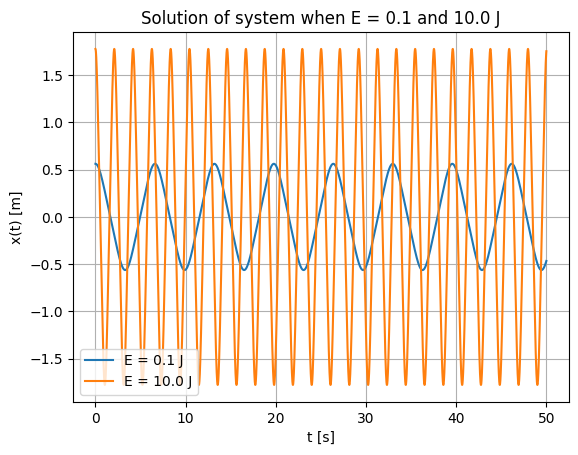

In [6]:
#Nonlinear Oscillator Part b.) 
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
from numpy.fft import rfft, irfft, rfftfreq

# initial conditions
E_i = [0.1, 10.0] #unit: J
x_0 = [E_i[0]**(1.0/4.0), E_i[1]**(1.0/4.0)] #intial condition for x(t=0) = E_i^(1/4) m from conservation of energy if v = 0. 
h = 1e-3 # step sizes of a system (s)

# initialize time arrays 
t = np.arange(0, 50000)*h #unit: seconnds 


#acceleration function
def acc(x): 
    """ This function calculates and stores entries for acceleration array used for leap-frog method of ODE's. 

    Parameter:
    ----------
    x: numpy array or list 
    Inputting position entries that correspond to acceleration values. 

    Return: 
    -------
    numpy array or float
    An array or float type that calculates and stores acceleration entries from corresponding x-values. 

    """
    ax = -4.0 * x**3
    return ax 
    


# Verlet process for either case
def solution(x_i):
    """This function essentially defines that solutions of the nonlinear oscillator system. 

    Parameters:
    ----------
    x_i: List
    x-initial conditions for each case 

    Return:
    ------
    List type
    List that contains the solutions to the system's equation of motion for each energy case.
    """
    # Initialize vectors;  x_pos is essentially the solution list.
    x_pos = []
    # Initialize acceleration (initial acceleration of the system)
    a_xi = acc(x_i) #unit: m/s^2
    v_0 = 0.0 # intial velocity v(t = 0) = 0 m/s 
    for i in range(50000): 
        #list append; start with initial condition for position (x_i) for particular case.
        x_pos.append(x_i)
        #start Verlet process with evaluating kinematics equation for position with defined initial position; later for iterative previous positions.
        x_f = x_i + v_0*h + 0.5*a_xi*h**2 
        #Jump to evaluating acceleration per just recently evaluated final position.
        a_xf = acc(x_f) 
        #Evaluate the kinematic relation for final velocity; 
        v_xf = v_0 + 0.5*(a_xi + a_xf)*h 
        #update; then recently evaluated kinetic terms get reset; rerun the loop with new casting.
        x_i = x_f
        v_0 = v_xf 
        a_xi = a_xf
    return x_pos

#plotting solution of nonlinear oscillator system for each energy case
plt.plot(t, solution(x_0[0]), label=f"E = {E_i[0]} J")
plt.plot(t, solution(x_0[1]), label=f"E = {E_i[1]} J")
plt.xlabel("t [s]")
plt.ylabel("x(t) [m]")
plt.title(f"Solution of system when E = {E_i[0]} and {E_i[1]} J")
plt.legend()
plt.grid(True)

 Based on visualization from period plot T(E = 0.1 J) = 6.550 s


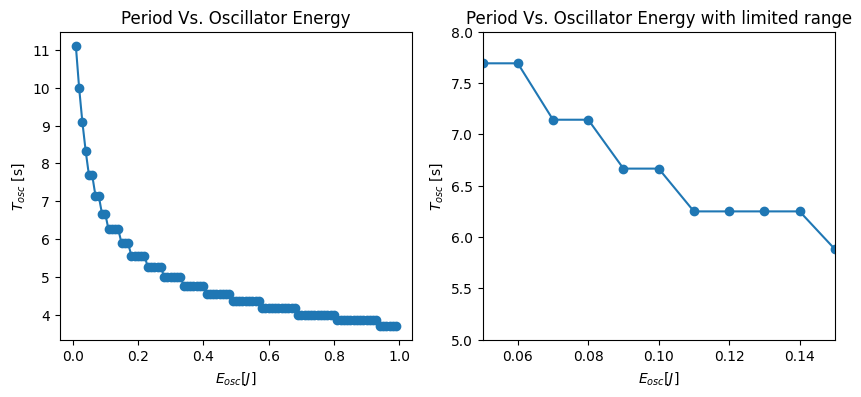

In [7]:
#Nonlinear Oscillator Part c.) 
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct

#energy array for use later 
E_i = np.arange(0.01, 1.0, 0.01) #unit: J 


#Acceleration and solution functions are copied here (previous block)
#acceleration function
def acc(x): 
    """ This function calculates and stores entries for acceleration array used for leap-frog method of ODE's. 

    Parameter:
    ----------
    x: numpy array or list 
    Inputting position entries that correspond to acceleration values. 

    Return: 
    -------
    numpy array or float
    An array or float type that calculates and stores acceleration entries from corresponding x-values. 

    """
    ax = -4.0 * x**3
    return ax 
    


# Verlet process for either case
def solution(x_i):
    """This function essentially defines that solutions of the nonlinear oscillator system. 

    Parameters:
    ----------
    x_i: List
    x-initial conditions for each case 

    Return:
    ------
    List type
    List that contains the solutions to the system's equation of motion for each energy case.
    """
    # Initialize vectors;  x_pos is essentially the solution list.
    x_pos = []
    # Initialize acceleration (initial acceleration of the system)
    a_xi = acc(x_i) #unit: m/s^2
    v_0 = 0.0 # intial velocity v(t = 0) = 0 m/s 
    for i in range(50000): 
        #list append; start with initial condition for position (x_i) for particular case.
        x_pos.append(x_i)
        #start Verlet process with evaluating kinematics equation for position with defined initial position; later for iterative previous positions.
        x_f = x_i + v_0*h + 0.5*a_xi*h**2 
        #Jump to evaluating acceleration per just recently evaluated final position.
        a_xf = acc(x_f) 
        #Evaluate the kinematic relation for final velocity; 
        v_xf = v_0 + 0.5*(a_xi + a_xf)*h 
        #update; then recently evaluated kinetic terms get reset; rerun the loop with new casting.
        x_i = x_f
        v_0 = v_xf 
        a_xi = a_xf
    return x_pos

#Function that does the DCT and calculates periods 
def DCT_per(x, h): 
    """ Function that does the discrete cosine transform and extracts periods. 

    Parameter: 
    x,h: array/List and float 
    essentially inputting solution lists of the nonlinear oscillator problem and stepsizes (h). 

    Return: 
    -------
    multiple array/List types 
    Return DCT, the absolute value of the DCT spectra, and the periods of the extracted system.

    """
    N = len(x) #sampling size 
    #apply DCT to solution array 
    X = dct(x) 
    # Taking the absoluteness of the DCT will help find the dominant modes. Take Abs. 
    abs_X = abs(X) 
    #finding k index values that define discrete frequencies
    k = np.argmax(abs_X)
    
    #Calculating frequencies for DCT: f_k = k/2*N*h 
    f_k = k/(2.0*N*h) #unit: s^-1
    #Extracting periods 
    T_k = 1.0/f_k #unit: s 
    return T_k, X, abs_X

#defining useful parameters() for the problem 
h = 1e-3 #unt: s; stepsize of system 
# initialize time arrays 
t = np.arange(0, 50000)*h #unit: seconnds 

#Initialize lists that will be used for plotting and the need for implementation
periods = [] 
DCT_plot = [] 
DCT_mag = [] 

#for loop that implements the problem 
for E in E_i: 
    #intialized positions
    x_i = E**(1.0/4.0) 
    #solution vectorized process 
    x_sol = solution(x_i) 
    #Extract DCT and period info 
    T_ex, X_ex, abs_X_ex = DCT_per(x_sol, h)
    #List append information 
    periods.append(T_ex) 
    DCT_plot.append(X_ex)
    DCT_mag.append(abs_X_ex) 

#plotting setup and defining frequency bins
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

#plotting eriod vs Osc energy and DCT 
axes[0].plot(E_i, periods, marker = "o")
axes[0].set_xlabel("$E_{osc} [J]$")
axes[0].set_ylabel("$T_{osc}$ [s]")
axes[0].set_title(f"Period Vs. Oscillator Energy")
#plotting to extract T(E= 0.1)
axes[1].plot(E_i, periods, marker = "o")
axes[1].set_xlabel("$E_{osc} [J]$")
axes[1].set_ylabel("$T_{osc}$ [s]")
axes[1].set_xlim(0.05, 0.15)
axes[1].set_ylim(5.0, 8.0)
axes[1].set_title(f"Period Vs. Oscillator Energy with limited range")
    

print(f" Based on visualization from period plot T(E = 0.1 J) = {(6.4 + 6.7)/2.0:.3f} s")



## The Deuteron (9 points)

A two-body system consisting of a neutron and a proton has only one **bound state**, the deuteron. Its ground state energy is with $E_b \approx -2.23$ MeV very small compared to the average mass of the neutron and proton, which is $m=938.926$ MeV. 

The **overall task of this exercise** is to compute the deuteron's ground state energy and associated wavefunction in momentum space. You may use standard `Python` packages.

The deuteron has the quantum numbers for the relative orbital momentum $l$, total spin $S$, and total angular momentum $J$. The ground state of the deuteron is mainly a $^3S_1$ state with a small admixture of a $^3D_1$ state, which we will neglect here for simplicity. Thus, we will consider only the $^3S_1$ component with quantum numbers $l=0$, $S=1$, and $J=1$.

Let's consider the simplistic model for the interaction between the neutron and proton, given by the **Malfliet-Tjon potential in momentum space**: 
\begin{equation} \boxed{
V(q)= \frac{1}{2\pi^2}\left( \frac{V_R}{q^2 + \mu_R^2} - \frac{V_A}{q^2 + \mu_A^2}
 \right) \,,}
\end{equation}
with the momentum transfer $q$ and the parameters:

\begin{align}
 V_{A} &= 626.8932 \, \mathrm{MeV\ fm} \,,\\
 \mu_{A} &= 1.550 \, \mathrm{fm}^{-1} \,,\\
 V_{R} &= 1438.7228 \, \mathrm{MeV\ fm} \,,\\
 \mu_{R} &= 3.11 \,{\mathrm{fm}}^{-1} \,.
\end{align}

The **(momentum-space) Schrödinger equation** we need to solve for the two particles (i.e., the neutron and proton) is given by
\begin{equation} \boxed{
(\hbar c)^2\frac{p^2}{2\mu}\psi_{nl}(p) + \int_0^\infty dp' p'^2 v_l(p,p')\psi_{nl}(p')=
E_n\psi_{nl}(p) \,,}
\end{equation}
where $\mu$ is the reduced mass of the two particles, $n$ the index of the eigensolutions, and $\hbar c = 197.3286$ MeV fm. We assume that the neutron and proton have equal masses such that $\mu = m/2$, where $m=938.926$ MeV is the average nucleon mass. The corresponding **partial-wave projected potential** is given by:
\begin{equation} \boxed{
v_l (p,p')= 2\pi \int_{-1}^{+1} d\cos \theta \; P_l(\cos \theta) \; V \left(\sqrt{p^2 +p'^2 -2pp'\cos \theta} \right) \,,}
\end{equation}
with the Legendre polynomials $P_l(\cos \theta)$ and momenta $p$ and $p'$. Note that the Schrödinger equation can be expressed as a matrix eigenvalue problem.

**Exercises:**

a) Write a `Python` function to compute $V(q)$ and plot the function over a sufficienlty large range in $q$. State the **units** of $q$ and $V(q)$ clearly in the axis labels. Qualitatively, where would you place the numerical quadrature points to obtain accurate results?

b) Write a `Python` function to compute $v_l(p, p')$ accurately. Print out the values of $v_{l=0}(p=0.5, p'=0.2)$ and $v_{l=2}(p=0.5, p'=0.2)$ (with units). Use the `print()` function with formatted strings. 

c) Plot $v_0(p, p')$ over a sufficently large range in $p$ and $p'$. Note that $v_0(p, p')$ is the _only_ partial-wave projected potential you will need for the remainder of this exercise. State all involved units clearly in the axis labels.

d) Specify explicitly the integral equation you aim to solve (i.e., momentum-space Schrödinger equation) and discuss the units of each term. State clearly what numerical procedure you will use to solve this integral equation, including details on discretizing the (improper) integral for numerical quadrature.
 
e) Calculate the deuteron binding energy and conduct a **convincing error analysis** that shows that your numerical result for the binding energy is accurate to _at least_ three significant figures.

f) Plot the normalized ground state wave function $\psi_{10}(q)$, with the normalization:

$$
\int dq \, q^2 \, |\psi_{10}(q)|^2 = 1 \,.
$$

 0<q<1/fm is the region that descibes variation (rise and dip) of potential and escapulates whole region, >5 1/fm potential varies close to zero.


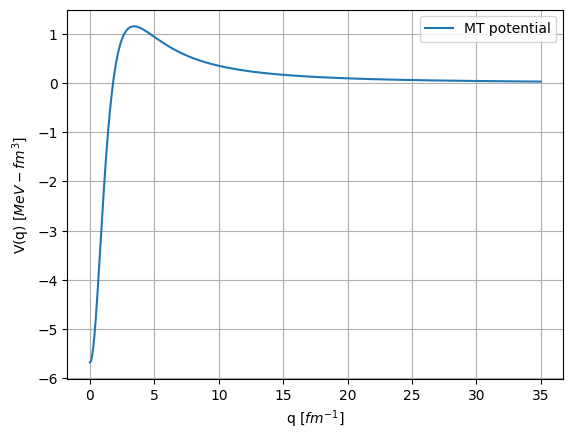

In [17]:
#Deuteron Part A.) 
import numpy as np
import matplotlib.pyplot as plt

#define useful constants 
V_A = 626.8932 #unit: MeV-fm 
mu_a = 1.550 #unit: fm^-1
mu_r = 3.11 #unit: fm^-1
V_R = 1438.7228 #unit: MeV-fm

#define MT_Potential 
def V_MT(q): 
    """ This function defines, calculates, and allocates MT-potential information. 

    Parameter: 
    ----------
    q: numpy array 
    An array that contains the momentum-transfer grid.


    Return: 
    ------
    numpy array 
    Each entry of MT-potential is calculated based on q-input from the array, then saved (later for plotting or other tasks). 

    """
    
    V = (1.0/(2.0*(np.pi)**2))*((V_R/(q**2 + mu_r**2)) - (V_A/(q**2 + mu_a**2)))
    return V 


#defining q-transfer array 
q = np.linspace(0.0, 35.0, 1000) #unit: fm^-1 
V_q = V_MT(q) 


#plotting of MT_potential
plt.plot(q, V_q, label=f"MT potential")
plt.xlabel("q [$fm^{-1}$]")
plt.ylabel("V(q) [$MeV-fm^{3}$]")
plt.legend()
plt.grid(True)


print(" 0<q<1/fm is the region that descibes variation (rise and dip) of potential and escapulates whole region, >5 1/fm potential varies close to zero.")

In [9]:
#Deuteron Part b.) 
import numpy as np 
import matplotlib.pyplot as plt 
from numpy.polynomial import Legendre as P

#quadrature information for partial wave potential form 
def partial_wave_Gauss_legendre(p, p_prime, l, f, N): 
    """This function essentially solves the partial-wave potential integral equation in Gauss-Legendre form.

    Parameter: 
    ----------
    p: float or array/list type. 
    p_prime: float or array/list type 
    l: int
    f: function (array type) 
    N: int 
    ----------
    The inputs correspond to relative-momentum terms in the Schrödinger equation that should be integrated out or left in. l, f, 
    and N corresponds to a particular Legendre term, MT_potential function, and the number of quadrature bins.  

    Returns: 
    --------
    float or array type (for plotting purposes) 
    It calculates and returns the partial-potential terms. 

    """
    
    # generate Legendre Polynomial 
    Leg = P.basis(N)

    # use roots() method to find roots (these will be cos values in kernel and others)
    roots = Leg.roots()

    # calculate derivatives of P3 at the roots
    Leg_prime = Leg.deriv(1)(roots)

    # calculate the weights
    w=[]
    for i in range(0, N, 1): 
        w.append(2.0/((1 - roots[i]**2)*(Leg_prime[i]**2)))

    #test function with roots inputted; define momemtum transfer q
    q = np.sqrt(p**2 + p_prime**2 - (2.0*p*p_prime*roots))
    function = f(q)

    #define integrand with specific Legendre basis
    Leg_l =  Leg = P.basis(l)(N)
    Integrand = Leg_l*function

    #dot product applied here 
    Integral = 2.0 * np.pi*np.dot(Integrand, w)

    return Integral 

# defining print statements 
v_l_0 = partial_wave_Gauss_legendre(0.5, 0.2, 1, V_MT, 500)
v_l_2 = partial_wave_Gauss_legendre(0.5, 0.2, 2, V_MT, 500)

print(f" v_l_0 = {v_l_0:.5f} MeV-fm^3, and v_l_2 = {v_l_2: .5f} MeV-fm^3")

 v_l_0 = -28272.29004 MeV-fm^3, and v_l_2 = -21204189.25770 MeV-fm^3


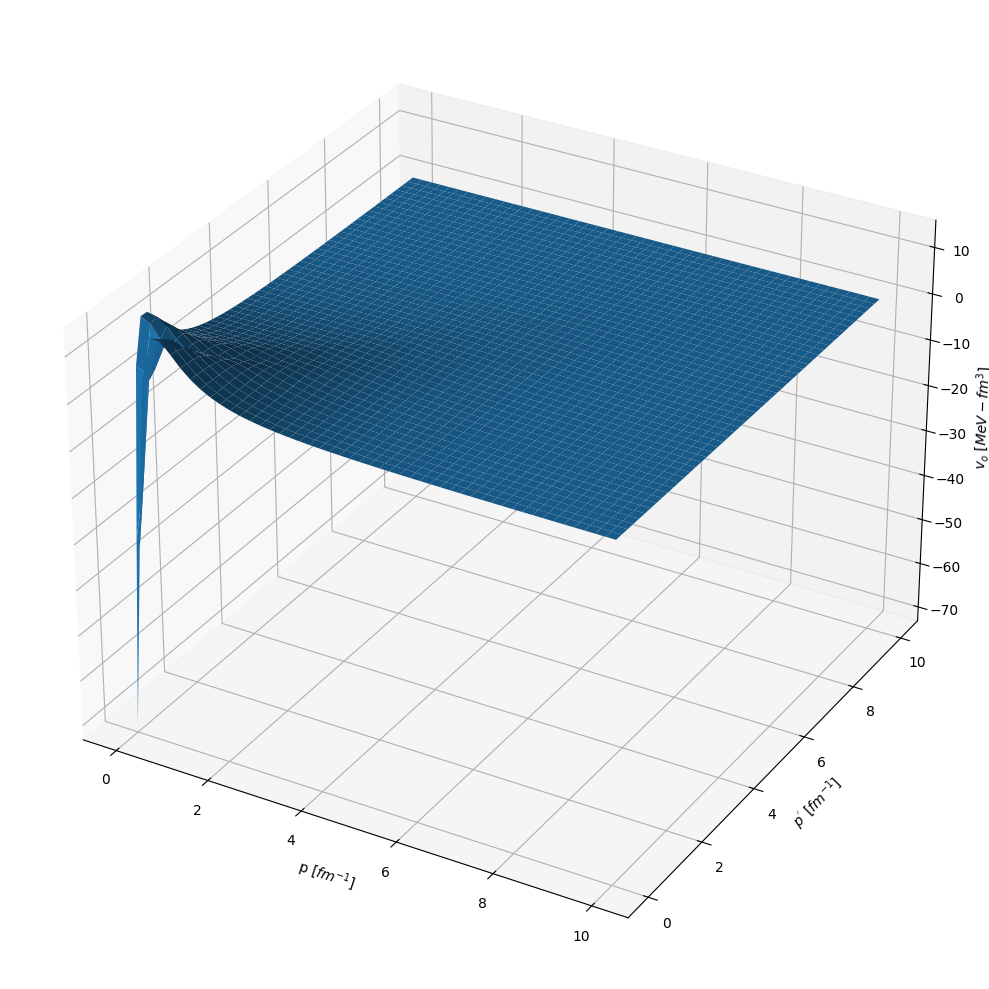

In [16]:
#Deuteron Part c.) 
from mpl_toolkits.mplot3d import Axes3D
import numpy as np 
import matplotlib.pyplot as plt 
from numpy.polynomial import Legendre as P


# momentum grids 
p = np.linspace(0.0, 10.0, 50)
p_prime = np.linspace(0.0, 10.0, 50)
p_dot, p_dot_prime = np.meshgrid(p, p_prime)

#make partial_potential matrix 
N = 50 #size of basis 
v_o = np.zeros((N,N)) 

#filling out elements of partial potential matrix
for i in range(len(p)): 
    for j in range(len(p)):
        v_o[i,j] =  partial_wave_Gauss_legendre(i, j, 0, V_MT, N)

#plotting 3D plot 
fig = plt.figure(figsize=(10, 15))
ax = fig.add_subplot(111, projection="3d")

# surface definition
ax.plot_surface(p_dot, p_dot_prime, v_o)
ax.set_xlabel("p [$fm^{-1}$]")
ax.set_ylabel("$p^{'}$ [$fm^{-1}$]")
ax.set_zlabel("$v_{o}$ [$MeV-fm^{3}$]")
plt.tight_layout()
plt.show()

In [32]:
#Deuteron Part d.) 

import numpy as np 
import matplotlib.pyplot as plt 
from numpy.polynomial import Legendre as P

"""
Plan of action for the problem: 
The overall goal is to obtain the ground-state energy and wave function. the ground state 
corresponds to quantum numbers n = 1, l = 0 (important to solving shrodinger equation). 
The overarching idea of solving this problem is 1. Construct the Hamiltonian matrix (kinetic + Pot Parts) 
linear algebra tools to get ground state eigenvalue and eigenvector, (BS energy = - ground state E). The ground state 
The wavefunction is obtained by defining the quadrature and finding the corresponding eigenvector. The steps below will correspond to building the Hamiltonian, how eigenvalues and eigenvectors are obtained,
and how wave functions are constructed. 


1. Hamiltonian: 


A.) Kinetic Energy: 

T = ((hbarc)^2*p*2/2*mu)*kronicker_ij(unitless)
- hbarc; unit: Mev-fm 
- p; unit: fm^-1 
- mu; unit: MeV 

(n = 1 already assumed for this formula, kinetic energy is made by a function that goes through a conditional statement, 
which is how to fill these elements.)

B.) Potential energy: 

- Implementation Plan: will transform the integral into the Gauss-Legendre problem using mapping p' = p_max/2(x + 1) (p_max representing upper bound).
  The partial-wave term will be calculated first, then applied using the new Gauss-Legendre mapping, and finally, the elements V will be defined.


  p': unit: fm^-1 


* Final Step is to define a function that creates Hamiltonian: H = T+V. 

2. eigen steps 

* Use linear algebra solver to get eigenvalues and eigenvectors. 


"""


#define kinetic energy form 
def T(N_basis, p):
    """ Kinetic energy matrix function 

    Parameter: 
    ---------
    N_basis, p: int, array 
    Input the momentum grid and basis size. 

    Return: 
    -------
    array type 
    Returns the kinetic energy array. 

    """
    
    hbarc = 197.3286 #unit: MeV-fm
    mu = (938.926/2.0) #unit: MeV
    T = ((hbarc**2)*p**2)/(2*mu)
    T_ij = np.diag(T) 
    return T_ij 


#define Potential energy matrix element function
def V_ij(p_prime,p_max, l, f, N_basis, N): 
    #partial wave and full_matrix definition
    v_l = np.zeros((N_basis,N_basis)) 
    V_ij = np.zeros((N_basis,N_basis)) 
    # Gauss-Legendre process for the integral of the potential term in the Schrodinger equation.
    x, w = np.polynomial.legendre.leggauss(N_basis)
    p = 0.5 * p_max * (x + 1.0)
    W = 0.5* p_max *w
    #filling out the elements' potential matrix
    for i in range(len(p)): 
        for j in range(len(p)):
            v_l =  partial_wave_Gauss_legendre(p_prime[i], p_prime[j], l, V_MT, N)
            V_ij[i,j] = W[j] * (p[j]**2) * v_l
    return V_ij


#Hamiltonian matrix 
def Hamiltonian(N_basis, p, p_max, l, f, N): 
    k = T(N_basis, p) 
    V = V_ij(p,p_max, l, f, N_basis, N) 
    H = k + V 
    return H 

